# Jewelry · 다이아몬드 가격 예측

# M1 데이터 불러오기

In [1]:
# mini-diamond 프로젝트를 만들고 scikit-learn · pandas · numpy · matplotlib · seaborn · ipykernel 을 설치한다.
# uv add pandas numpy seaborn scikit-learn matplotlib ipykernel 

# 노트북 첫 셀에 import 와 한글 폰트 설정을 넣는다(1장 2강 Lab 7 셀 재사용).
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"

# sns.load_dataset("diamonds") 로 불러와 df 에 담고, 크기와 앞 5행을 본다.
df = sns.load_dataset("diamonds")
print(df.shape)
df.head()
# (53940, 10)

(53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [2]:
# 각 열의 자료형과 빈칸 개수를 확인한다.
df.info()
print("="*20)
print("빈칸 개수 :",df.isnull().sum().sum())


<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB
빈칸 개수 : 0


In [3]:
# 숫자 열의 기초 통계를 보고 이상해 보이는 값을 두 가지 이상 찾아 적는다.
print(df.describe())
# x, y , z 의 min 값이 0 입니다.
# x 는 잘 모르겠지만 y , z 의 max 값은 이상합니다.  
for ii in ["x","y","z"] :
    q1 = df[ii].quantile(0.25)
    q3 = df[ii].quantile(0.75)
    iqr = q3 - q1
    min = q1 - 1.5 * iqr
    max = q3 + 1.5 * iqr
    print(f"{ii}_Q1: {q1}")
    print(f"{ii}_Q3: {q3}")
    print(f"{ii}_IQR: {iqr}")
    print(f"{ii}_min: {min}")
    print(f"{ii}_max: {max}")
    print("=="*20)
# price 의 50% 값과 mean 값의 오차가 상당합니다   
# mean:3932.799722 , 50% :2401.000000

              carat         depth         table         price             x  \
count  53940.000000  53940.000000  53940.000000  53940.000000  53940.000000   
mean       0.797940     61.749405     57.457184   3932.799722      5.731157   
std        0.474011      1.432621      2.234491   3989.439738      1.121761   
min        0.200000     43.000000     43.000000    326.000000      0.000000   
25%        0.400000     61.000000     56.000000    950.000000      4.710000   
50%        0.700000     61.800000     57.000000   2401.000000      5.700000   
75%        1.040000     62.500000     59.000000   5324.250000      6.540000   
max        5.010000     79.000000     95.000000  18823.000000     10.740000   

                  y             z  
count  53940.000000  53940.000000  
mean       5.734526      3.538734  
std        1.142135      0.705699  
min        0.000000      0.000000  
25%        4.720000      2.910000  
50%        5.710000      3.530000  
75%        6.540000      4.040000  


# M2 이상치 정리
- 목표 : 말이 안되는 값을 찾아 근거와 함께 제거하고 , 정리된 표 clean 을 만든다.


In [4]:
# x · y · z 각각 0 인 값이 몇 개인지 센다.
for i in ["x","y","z"]:
    print(f"{i} : {(df[i] == 0).sum()}개")

x : 8개
y : 7개
z : 20개


In [5]:
# 셋 중 하나라도 0 인 행이 몇 개인지 세고, 그 행들을 직접 본다.
or_df = df[(df["x"] == 0) | (df["y"] == 0) | (df["z"] == 0)]
print("셋 중 하나라도 0인 행의 숫자 : ",len(or_df))
print(or_df)

셋 중 하나라도 0인 행의 숫자 :  20
       carat        cut color clarity  depth  table  price     x     y    z
2207    1.00    Premium     G     SI2   59.1   59.0   3142  6.55  6.48  0.0
2314    1.01    Premium     H      I1   58.1   59.0   3167  6.66  6.60  0.0
4791    1.10    Premium     G     SI2   63.0   59.0   3696  6.50  6.47  0.0
5471    1.01    Premium     F     SI2   59.2   58.0   3837  6.50  6.47  0.0
10167   1.50       Good     G      I1   64.0   61.0   4731  7.15  7.04  0.0
11182   1.07      Ideal     F     SI2   61.6   56.0   4954  0.00  6.62  0.0
11963   1.00  Very Good     H     VS2   63.3   53.0   5139  0.00  0.00  0.0
13601   1.15      Ideal     G     VS2   59.2   56.0   5564  6.88  6.83  0.0
15951   1.14       Fair     G     VS1   57.5   67.0   6381  0.00  0.00  0.0
24394   2.18    Premium     H     SI2   59.4   61.0  12631  8.49  8.45  0.0
24520   1.56      Ideal     G     VS2   62.2   54.0  12800  0.00  0.00  0.0
26123   2.25    Premium     I     SI1   61.3   58.0  15397  8.52

In [6]:
# y 나 z 가 20mm 를 넘는 행을 찾아 직접 본다. 왜 이상한 값이라고 판단할 수 있는지 적는다.
q_3_20_over = df[(df["y"] > 20) | (df["z"] > 20)]
print(q_3_20_over)
# 크기에 비해 캐럿이 적음

       carat        cut color clarity  depth  table  price     x      y      z
24067   2.00    Premium     H     SI2   58.9   57.0  12210  8.09  58.90   8.06
48410   0.51  Very Good     E     VS1   61.8   54.7   1970  5.12   5.15  31.80
49189   0.51      Ideal     E     VS1   61.8   55.0   2075  5.15  31.80   5.12


In [7]:
# 두 종류의 이상한 행을 모두 뺀 clean 표를 만들고, 제거 전후 행 수를 출력한다.
not_clean = (df["x"] == 0) | (df["y"] == 0) | (df["z"] == 0) |(df["y"] > 20) | (df["z"] > 20)
q_4_list_err = df[not_clean]
print("이상한 행 :",len(q_4_list_err),"개")
print("제거 전 행 수:",len(df),"개")
q_4_list_clean = df[~not_clean].copy()
print("제거 후 행 수:",len(q_4_list_clean),"개")
print(q_4_list_clean)


이상한 행 : 23 개
제거 전 행 수: 53940 개
제거 후 행 수: 53917 개
       carat        cut color clarity  depth  table  price     x     y     z
0       0.23      Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1       0.21    Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2       0.23       Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3       0.29    Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4       0.31       Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75
...      ...        ...   ...     ...    ...    ...    ...   ...   ...   ...
53935   0.72      Ideal     D     SI1   60.8   57.0   2757  5.75  5.76  3.50
53936   0.72       Good     D     SI1   63.1   55.0   2757  5.69  5.75  3.61
53937   0.70  Very Good     D     SI1   62.8   60.0   2757  5.66  5.68  3.56
53938   0.86    Premium     H     SI2   61.0   58.0   2757  6.15  6.12  3.74
53939   0.75      Ideal     D     SI2   62.2   55.0   2757  5.83  5.87  3.64

[53917 rows x 10 columns]


# M3 그래프와 상관계수
- 목표 : 가격의 분포와 무게-가격 관계를 그리고, 가격을 예측할 특성 하나를 고른다.

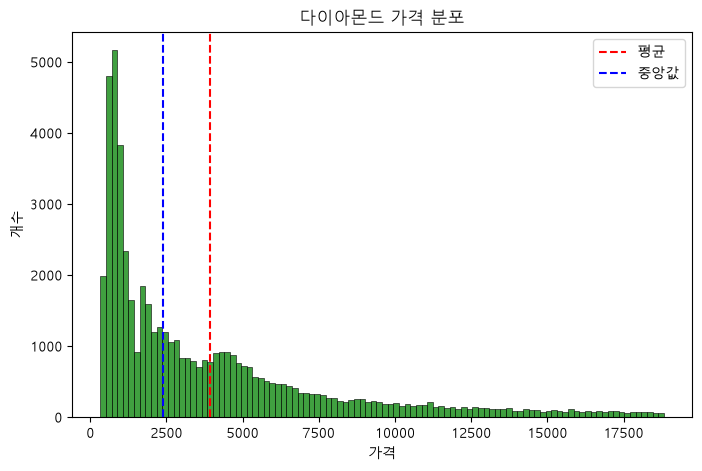

In [8]:
# price 의 히스토그램을 그리고 평균 · 중앙값을 세로선으로 표시한다.
fig, ax = plt.subplots(figsize=(8, 5))
# 평균과 중앙값
price_mean = df["price"].mean()
price_median = df["price"].median()

# 히스토그램
sns.histplot(data=df, x="price",color="green", bins = 100 , ax=ax)

# 세로선 표시
ax.axvline(x = price_mean, color="red", linestyle="--", label="평균")
ax.axvline(x = price_median, color="blue", linestyle="--", label="중앙값")

ax.set_title("다이아몬드 가격 분포")
ax.set_xlabel("가격")
ax.set_ylabel("개수")

# 범례 표시
ax.legend()

plt.show()

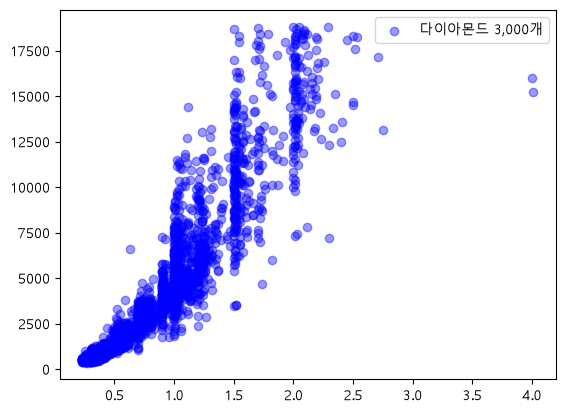

In [9]:
# carat 과 price 의 산점도를 그린다(점이 많으면 3,000개만 무작위로 뽑아 그린다).

n_df = df.sample(3000, random_state= 42)
plt.Figure(figsize=(10,4))
plt.scatter(n_df["carat"],n_df["price"], color="blue", alpha=0.4, label="다이아몬드 3,000개")
plt.legend()
plt.show()

In [10]:
# 숫자 열끼리 상관계수를 구해 price 와 상관이 큰 순서로 정렬한다.
print(n_df)
n_word = ["carat","depth","table","price"]
print("숫자 열끼리 상관 계수 \n",n_df[n_word].corr()["price"].drop("price").sort_values(ascending=False))

       carat        cut color clarity  depth  table  price     x     y     z
1388    0.24      Ideal     G    VVS1   62.1   56.0    559  3.97  4.00  2.47
50052   0.58  Very Good     F    VVS2   60.0   57.0   2201  5.44  5.42  3.26
41645   0.40      Ideal     E    VVS2   62.1   55.0   1238  4.76  4.74  2.95
42377   0.43    Premium     E    VVS2   60.8   57.0   1304  4.92  4.89  2.98
17244   1.55      Ideal     E     SI2   62.3   55.0   6901  7.44  7.37  4.61
...      ...        ...   ...     ...    ...    ...    ...   ...   ...   ...
24103   2.01  Very Good     J     SI1   59.3   62.0  12257  8.15  8.20  4.85
9125    0.90    Premium     F     VS2   61.9   55.0   4536  6.25  6.23  3.86
41100   0.50       Good     I     VS1   61.2   61.0   1193  5.03  5.06  3.09
42361   0.61       Good     I     VS2   63.4   55.0   1303  5.42  5.46  3.45
49495   1.00       Fair     J     SI2   69.9   61.0   2117  6.13  5.86  4.23

[3000 rows x 10 columns]
숫자 열끼리 상관 계수 
 carat    0.924487
table    0.141906

# 가격 예측에 쓸 특성 하나를 고르고 이유를 적는다.
> 산점도 분포표를 보면 캐럿이 높을수록 가격이 높게 분포되어있습니다. <br> 그리고 상관계수를 보아도 캐럿과 가격이 상관이 크기 때문에 캐럿이 가격 예측에 적당한 특성이라고 생각합니다.


# M4 무게로 가격 예측
- 목표 : carat 하나로 선형 회귀를 학습해 w · b 의 뜻을 설명하고, 새 다이아몬드의 가격을 예측하고, 직선을 그림으로 확인한다.

In [11]:
# carat 열 하나로 LinearRegression 을 학습하고 w(기울기) · b(절편)를 출력한다.

from sklearn.linear_model import LinearRegression

X = n_df[["carat"]] 


y = n_df["price"] 
model = LinearRegression()
model.fit(X,y)

print(f"기울기: {model.coef_[0]:.2f}")
print(f"절편: {model.intercept_:.2f}")

기울기: 7707.88
절편: -2240.29


# w 의 뜻을 한 문장으로 적는다(“무게가 1캐럿 늘면 …”)
- 캐럿이 늘어나면 가격도 비례해서 올라간다

In [12]:
# 0.25 · 0.5 · 1.0 · 2.0 캐럿 다이아몬드의 가격을 예측한다. 이상한 결과가 있나?
ex_price =[0.25,0.5,1.0,2.0]
new_data = pd.DataFrame(ex_price, columns=["carat"])
predicted_price = model.predict(new_data)
for carat , n_price in zip(ex_price , predicted_price) :
    print(f"carat : {carat} , 가격: {n_price} , 상태: {"비정상" if n_price < 0 else "정상"} ")

# carat : 0.25   , 가격: -313.31597596539336 , 상태: 비정상         0보다 작은 가격이 나와버렸습니다.

carat : 0.25 , 가격: -313.31597596539336 , 상태: 비정상 
carat : 0.5 , 가격: 1613.654137838324 , 상태: 정상 
carat : 1.0 , 가격: 5467.594365445759 , 상태: 정상 
carat : 2.0 , 가격: 13175.474820660627 , 상태: 정상 


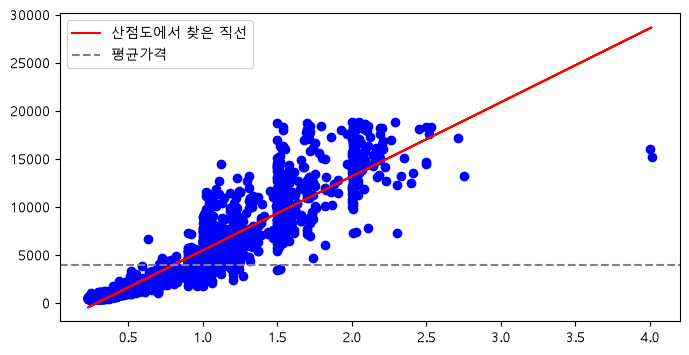

In [13]:
# 데이터 3,000개의 산점도에 찾은 직선(빨강)과 평균 가격(회색 가로선)을 겹쳐 그린다.
y_pred = model.predict(X)
# print("학습 데이터에 대한 예측값:", y_pred)
plt.figure(figsize=(8,4))
# 산점도
plt.scatter(X["carat"], y, color="blue", label="")
# 회귀직선
plt.plot(X["carat"], y_pred, color="red", label="산점도에서 찾은 직선")
plt.axhline(n_df["price"].mean(), color="gray", linestyle="--" , label="평균가격")
plt.legend()
plt.show()

## M5 · 특성 하나씩 직선 만들기
- 목표 : 숫자 6개 열 각각 하나로 직선을 만들어 그림으로 비교하고, 가격을 예측할 열을 고른 이유를 설명한다.

### 숫자 6개 열 각각 하나로 LinearRegression 을 학습한다.

In [14]:


from sklearn.linear_model import LinearRegression

nums = ["carat","depth","table","x","y","z"]
models = {}
for i in nums:
    X = n_df[[i]]
    y = n_df["price"]
    model_item = LinearRegression()
    model_item.fit(X,y)
    # print(f"항목: {i}")
    # print(f"기울기: {model_item.coef_[0]:.2f}")
    # print(f"절편: {model_item.intercept_:.2f}")
    models[i] = model_item

### 데이터 3,000개의 산점도와 각 열의 직선을 2행 3열 그림 한 장에 그린다.

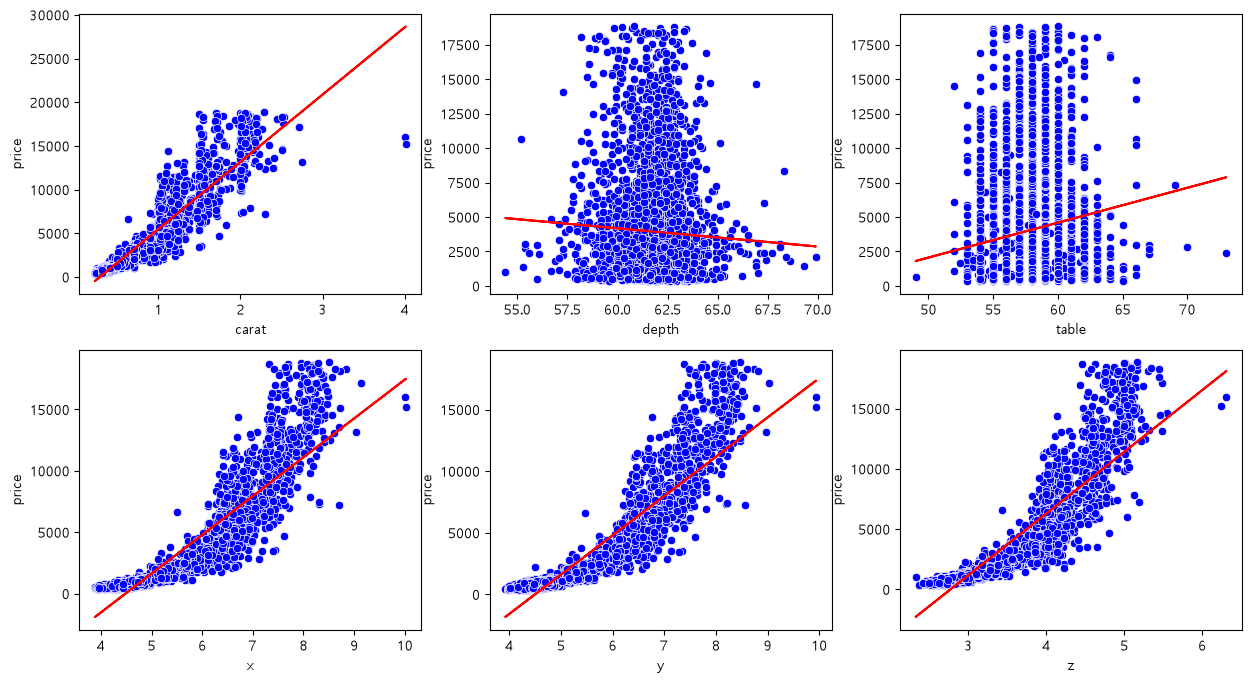

In [15]:

fig, axes = plt.subplots(2,3, figsize=(15,8))
axes = axes.flatten() # 2차원 배열이라 사용
sam_n_df = n_df.sample(3000, random_state= 42)

for idx , col in enumerate(nums) :
    # 산점도
    sns.scatterplot(     
        data = sam_n_df,
        x = col,
        y = "price",
        color = "blue",
        ax =axes[idx]
    )
    # 각 열의 직선
    X = sam_n_df[[col]]   
    predicted_price = models[col].predict(X)
    
    axes[idx].plot(
        X,
        predicted_price,
        color="red"
    )

# 직선이 점들을 잘 따라가는 열과 못 따라가는 열을 적는다.
- 직선이 점들을 따라가는 열 :  carat, x , y , z

- 직선이 점들을 따라가지 못하는 열 : depth , table
 


### 열마다 w(기울기)와 열의 범위(가장 작은 값 ~ 가장 큰 값)를 표 하나로 정리하고, w 가 크면 더 좋은 열인지 생각해 적는다.



In [24]:
from sklearn.metrics import r2_score 
new_df = []
for col in nums:
    X = sam_n_df[[col]]
    y = sam_n_df["price"]
    predicted_price = models[col].predict(X)
    r2 = round(r2_score(y, predicted_price),2)
    new_df.append({
        "항목":         col,
        "기울기(W)":    models[col].coef_[0],
        "최소값":       sam_n_df[col].min(),
        "최대값":       sam_n_df[col].max(),
        "결정계수":     r2
    })
result_df = pd.DataFrame(new_df)
result_df




,항목,기울기(W),최소값,최대값,결정계수
0,carat,7707.880455,0.23,4.01,0.85
1,depth,-132.710558,54.40,69.90,0.00
2,table,253.253505,49.00,73.00,0.02
3,x,3159.010398,3.88,10.02,0.79
4,y,3188.243915,3.92,9.94,0.80
5,z,5114.598455,2.32,6.31,0.78


### w 가 크면 더 좋은 열인지 생각해 적는다.
> w는 열의 단위가 달라 크기를 비교할 수 없습니다.<br> carat 과 price는 상관계수도 높았고 결정 계수 역시 carat이 가장높습니다.<br> 그러므로 carat이 가장 가격을 예측할 열에 적압하다 판단됩니다.

### M3 의 상관계수 순서와 그림이 같은 이야기를 하는지 확인한다.
> M3의 상관계수 순서 역시 같은 모습을 보여주고 있습니다